# Where does deforestation cluster in Colombia?

Hansen GFC 2001-2025 in 5 km hexagons for the **Amazon deforestation arc** (Meta, Guaviare, Caquetá, Putumayo) and **Chocó**.

This notebook reproduces the key steps from the processed hexagons in `data/processed`:

1. **Agent step**: the [gis-mcp](https://github.com/mahdin75/gis-mcp) server is launched over stdio and its PySAL tools are called through an MCP client, as an AI host would do.
2. **Script step**: the same statistics are recomputed with `esda`, adding Gi\*, 9,999 permutations and a False Discovery Rate correction.
3. The VT0007-style comparison is read from `results/` (the full test needs the 90 m rasters; see `scripts/05_vt0007_benchmark.py`).

## 0. Setup

gis-mcp 0.15 pins old versions of numpy and rasterio, so it is installed in its own environment and run as a separate process. In Colab this takes a couple of minutes.

In [1]:
import os, sys, subprocess, shutil

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("deforestation-hotspots-colombia"):
        subprocess.run(["git", "clone", "-q", "https://github.com/albertolozada/deforestation-hotspots-colombia.git"], check=True)
    os.chdir("deforestation-hotspots-colombia")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "esda", "libpysal", "mcp", "uv"], check=True)
    subprocess.run(["uv", "venv", "-q", "--python", "3.12", "/content/gismcp"], check=True)
    subprocess.run(["uv", "pip", "install", "-q", "--python", "/content/gismcp/bin/python", "gis-mcp==0.15.0"], check=True)
    GIS_MCP = "/content/gismcp/bin/gis-mcp"
else:
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    GIS_MCP = os.environ.get("GIS_MCP") or shutil.which("gis-mcp")
print("gis-mcp executable found:", bool(GIS_MCP and os.path.exists(GIS_MCP)))

gis-mcp executable found: True


In [2]:
import json
import geopandas as gpd
import numpy as np
import pandas as pd
import esda, libpysal
from IPython.display import Image, display
from mcp import Client, StdioServerParameters

LAEA_COL = "+proj=laea +lat_0=4 +lon_0=-73.5 +x_0=0 +y_0=0 +datum=WGS84 +units=m +no_defs"
BAND_M = 5500.0   # first ring of 5 km hexagons
hexes = {r: gpd.read_file(f"data/processed/hex5km_{r}_stats.gpkg") for r in ["amazon_arc", "choco"]}
{r: len(g) for r, g in hexes.items()}

{'amazon_arc': 11841, 'choco': 2214}

## 1. Check the CRS first

The hexagons are in an equal-area projection in metres, so the 5.5 km band is a real distance.

In [3]:
for r, g in hexes.items():
    print(r, "| geographic:", g.crs.is_geographic, "| units:", g.crs.axis_info[0].unit_name,
          "| hexagon area km2:", round(g.geometry.area.median() / 1e6, 2))

amazon_arc | geographic: False | units: metre | hexagon area km2: 21.65
choco | geographic: False | units: metre | hexagon area km2: 21.65


## 2. Agent step: gis-mcp through MCP

The variable is the annual tree cover loss rate in 2017-2025 (% of the forest in 2016). Hexagons without a rate, and the few left without any neighbour, are excluded first, because gis-mcp silently drops isolated units from its local outputs.

In [4]:
def prepare(g, var):
    sub = g[g[var].notna()].reset_index(drop=True)
    w0 = libpysal.weights.DistanceBand.from_dataframe(sub, threshold=BAND_M, binary=True, silence_warnings=True)
    return sub.drop(index=w0.islands).reset_index(drop=True)

SERVER = StdioServerParameters(command=GIS_MCP, args=[])

async def gis_mcp(tool, path, var):
    async with Client(SERVER) as client:
        res = await client.call_tool(tool, {"shapefile_path": path, "dependent_var": var,
                                            "target_crs": LAEA_COL, "distance_threshold": BAND_M})
    return json.loads(res.content[0].text)

tool_results = {}
for r, g in hexes.items():
    sub = prepare(g, "rate_p3")
    path = os.path.abspath(f"data/processed/_nb_{r}.gpkg")
    sub[["hex_id", "rate_p3", "geometry"]].to_file(path, driver="GPKG")
    out = await gis_mcp("morans_i", path, "rate_p3")
    tool_results[r] = (sub, out["result"])
    print(r, "|", out["message"], "| I =", round(out["result"]["I"], 4), "| p =", out["result"]["p_value"])

amazon_arc | Moran's I completed successfully (threshold: 5500.0 meters) | I = 0.8018 | p = 0.001


choco | Moran's I completed successfully (threshold: 5500.0 meters) | I = 0.6035 | p = 0.001


## 3. Script step: confirm with esda, then Gi\* with FDR

In [5]:
rows = []
for r, (sub, res) in tool_results.items():
    y = sub["rate_p3"].to_numpy(float)
    w_tool = libpysal.weights.DistanceBand.from_dataframe(sub, threshold=BAND_M, binary=False, silence_warnings=True)
    w_tool.transform = "r"
    moran = esda.Moran(y, w_tool, permutations=999)

    w = libpysal.weights.DistanceBand.from_dataframe(sub, threshold=BAND_M, binary=True, silence_warnings=True)
    gstar = esda.G_Local(y, w, transform="B", star=True, permutations=9999, seed=20261109)
    sig = gstar.p_sim <= esda.fdr(gstar.p_sim, 0.05)
    hot = sig & (gstar.Zs > 0)
    rows.append({"region": r, "hexagons": len(sub), "Moran's I gis-mcp": round(res["I"], 4),
                 "Moran's I esda": round(float(moran.I), 4), "hot spots (Gi*, FDR 5 %)": int(hot.sum()),
                 "share of area %": round(hot.mean() * 100, 1),
                 "share of loss %": round(sub.loc[hot, "loss_p3_ha"].sum() / sub["loss_p3_ha"].sum() * 100, 1)})
pd.DataFrame(rows)

,region,hexagons,Moran's I gis-mcp,Moran's I esda,"hot spots (Gi*, FDR 5 %)",share of area %,share of loss %
0,amazon_arc,11384,0.8018,0.8018,1365,12.0,60.1
1,choco,2214,0.6035,0.6035,112,5.1,48.1


The values match `results/spatial_autocorrelation_summary.csv`, produced by `scripts/04_spatial_stats.py` for the three periods:

In [6]:
pd.read_csv("results/spatial_autocorrelation_summary.csv")[
    ["region", "period", "hexagons", "morans_i_gis_mcp", "morans_i_esda", "hot_spots",
     "share_of_area_in_hot_spots_pct", "share_of_loss_in_hot_spots_pct"]]

,region,period,hexagons,morans_i_gis_mcp,morans_i_esda,hot_spots,share_of_area_in_hot_spots_pct,share_of_loss_in_hot_spots_pct
0,amazon_arc,2001-2008,11401,0.7981,0.7981,1200,10.5,54.5
1,amazon_arc,2009-2016,11395,0.7905,0.7905,1081,9.5,54.4
2,amazon_arc,2017-2025,11384,0.8018,0.8018,1365,12.0,60.1
3,choco,2001-2008,2214,0.6568,0.6568,80,3.6,38.5
4,choco,2009-2016,2214,0.6085,0.6085,36,1.6,29.5
5,choco,2017-2025,2214,0.6035,0.6035,112,5.1,48.1


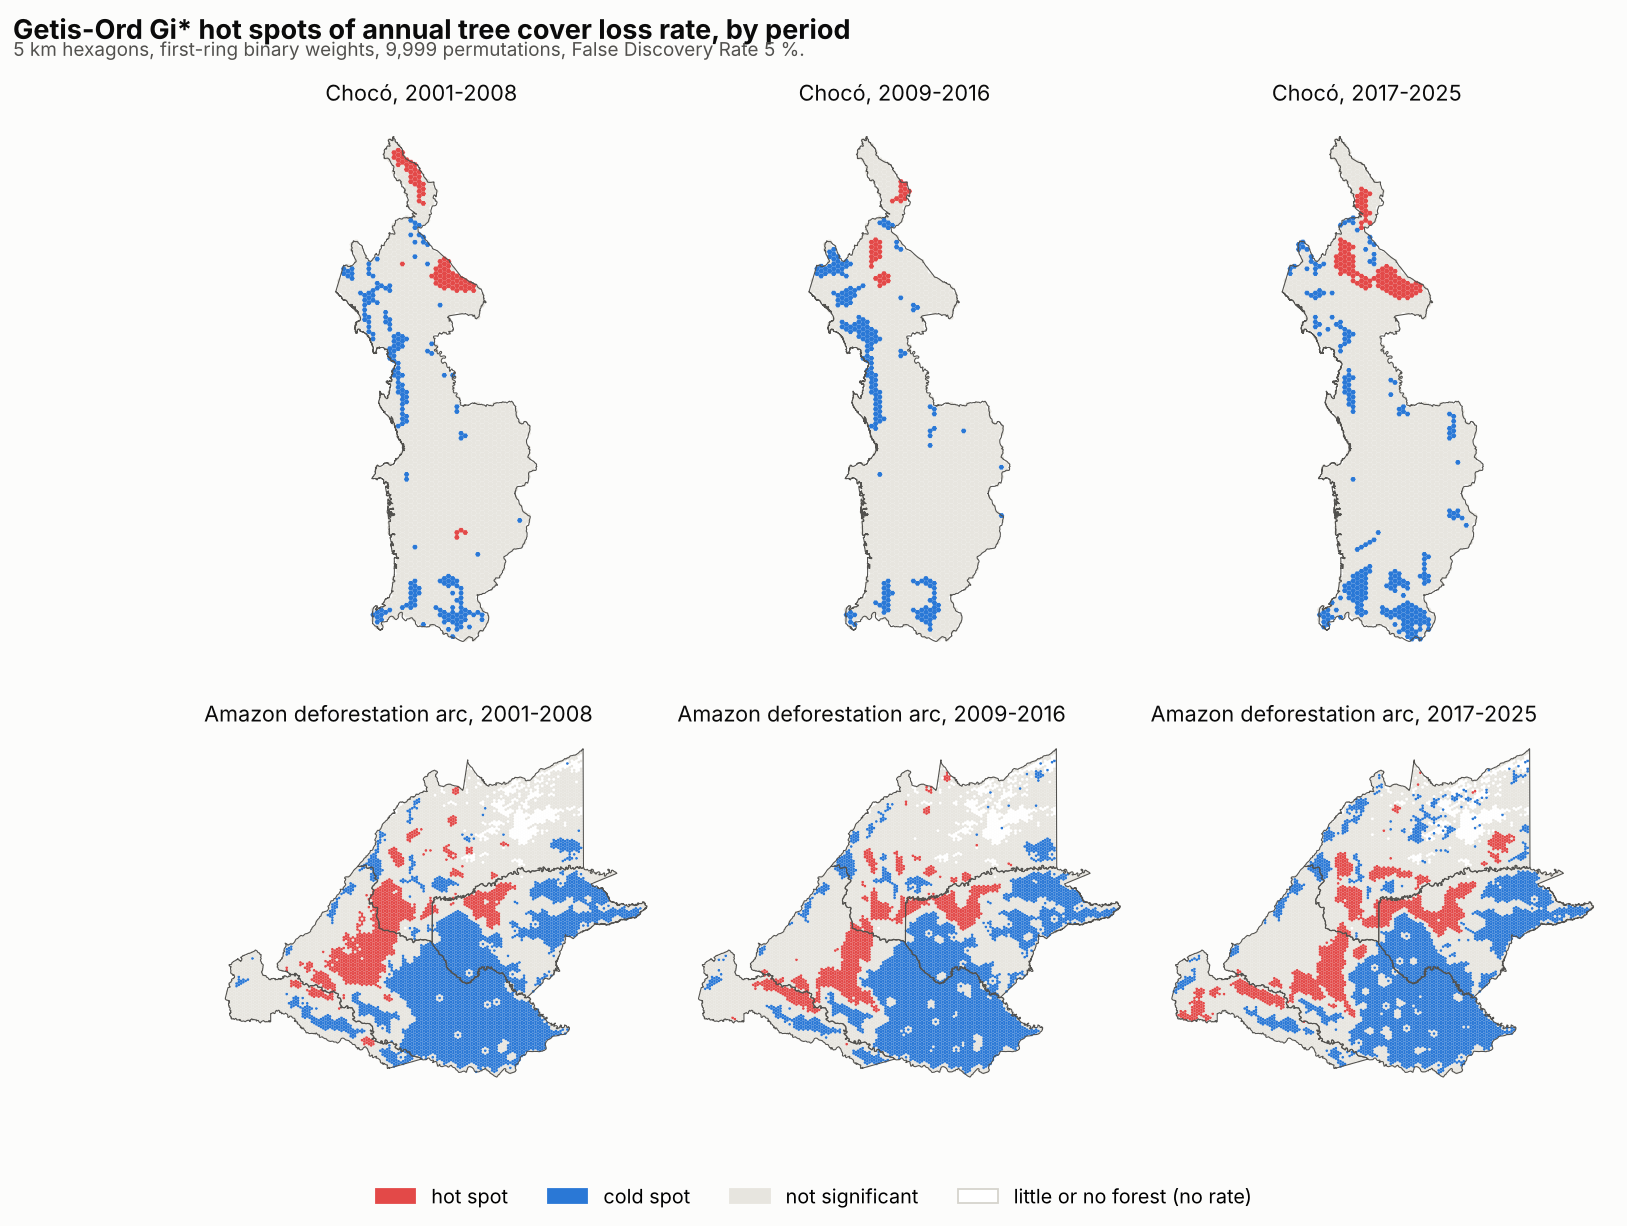

In [7]:
display(Image("outputs/maps/hotspot_migration.png", width=900))

## 4. Link with VM0048: a VT0007-style benchmark with and without hot spots

Median absolute error (ha) per 5 km hexagon, fitting on one period and predicting the next. See the README for the method and its simplifications.

In [8]:
pd.read_csv("results/vt0007_benchmark_vs_hotspot_alternative.csv")

,region,test,fit,predict,nrt_m,observed_loss_ha,medae_benchmark_ha,medae_alternative_ha,mae_benchmark_ha,mae_alternative_ha,alternative_better
0,choco,test 1,2001-2008,2009-2016,6940,48770,12.609,9.438,23.75,22.51,True
1,choco,test 2,2009-2016,2017-2025,4695,56123,18.596,14.297,30.92,28.96,True
2,amazon_arc,test 1,2001-2008,2009-2016,3643,596935,19.867,10.000,44.88,36.88,True
3,amazon_arc,test 2,2009-2016,2017-2025,4061,1182961,45.469,24.578,95.83,81.91,True


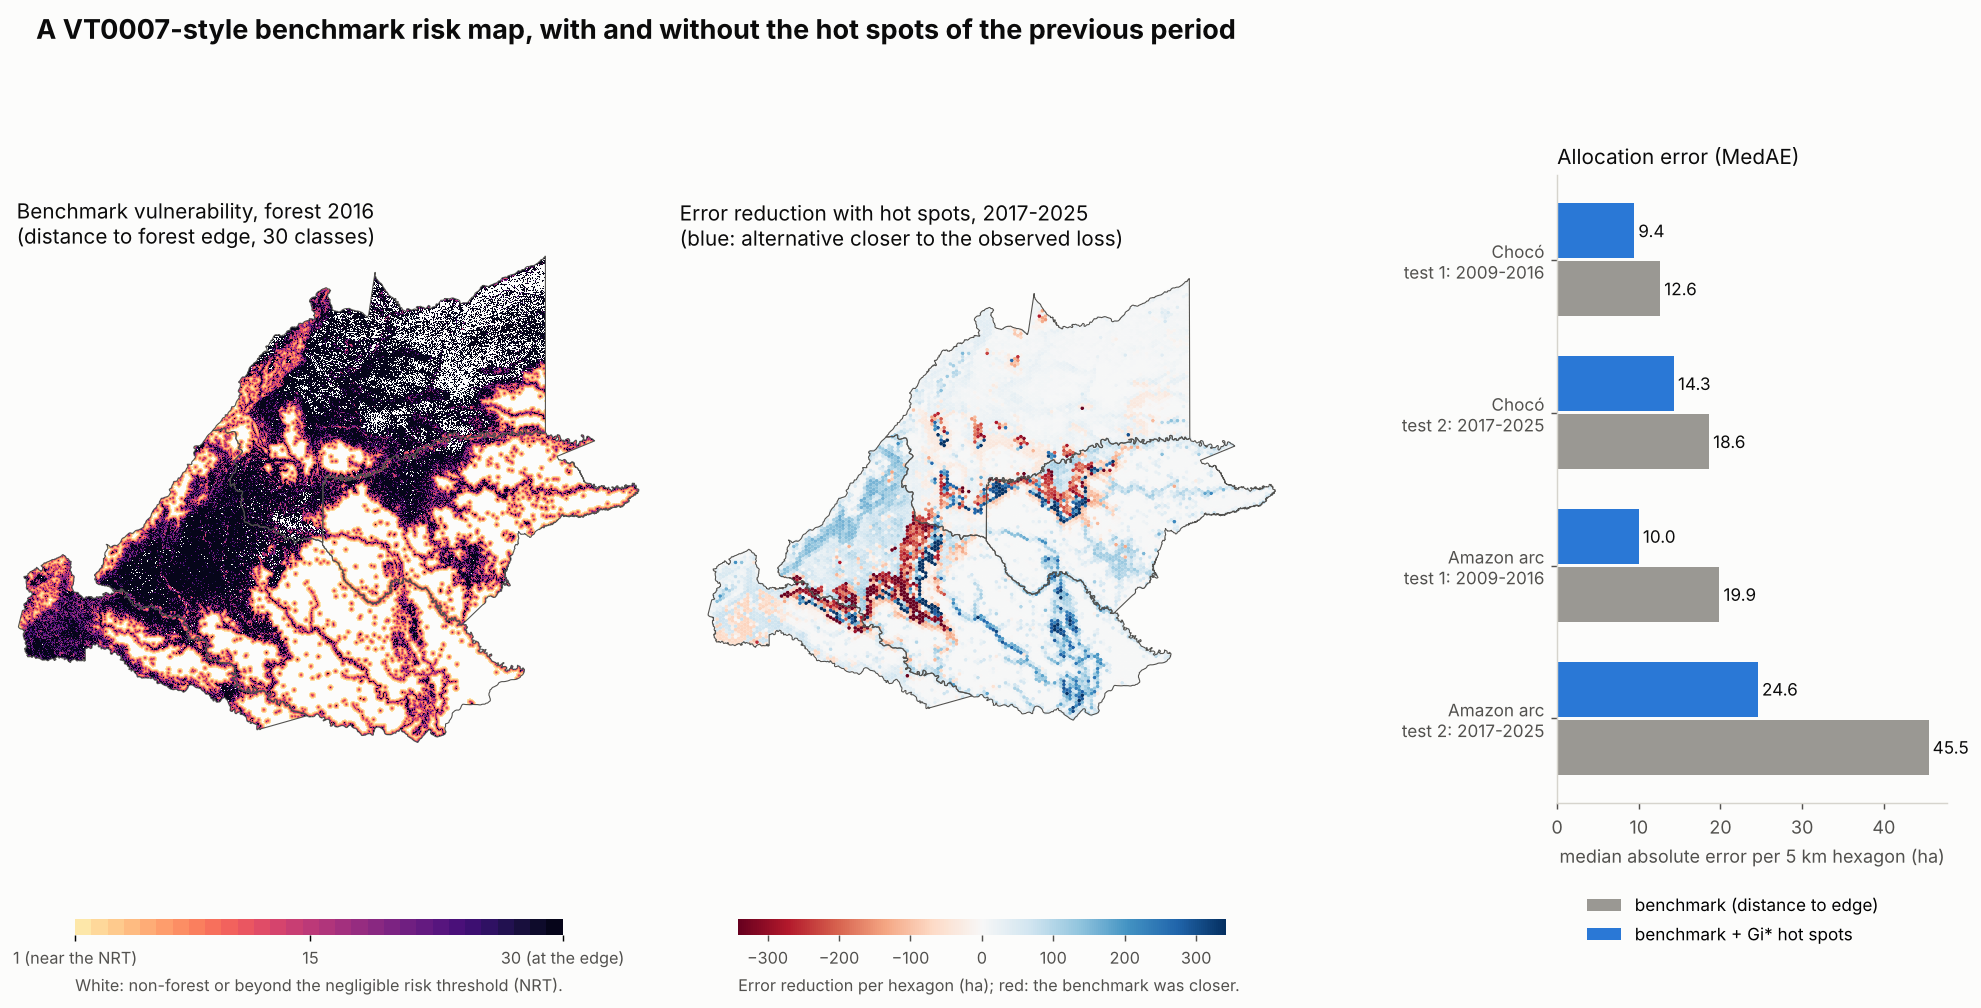

In [9]:
display(Image("outputs/maps/vt0007_comparison.png", width=900))

## Conclusions

- Tree cover loss is strongly clustered in both regions (Moran's I about 0.80 in the Amazon arc and 0.60 in Chocó), and gis-mcp and esda agree.
- In 2017-2025, 60 % of the loss in the Amazon arc happened in hot spots covering 12 % of the area.
- Splitting a VT0007-style benchmark by the hot spots of the previous period roughly halves the allocation error in the Amazon arc, in both tests.

**Limitations:** Hansen tree cover loss is not official deforestation data; the VT0007 test is a simplified illustration, not the official tool.